# Analisis dan Preprocessing Data UMKM ROKKUS Mardani Raya

## Deskripsi Proyek

Notebook ini berisi proses analisis dan preprocessing data persediaan produk UMKM ROKKUS Mardani Raya menggunakan Python dan Pandas.

Dataset yang digunakan merupakan dataset sintetis dengan periode 1–30 September 2026, yang terdiri dari:
- Master Produk: 29 data produk.
- Stok Awal: 29 data produk.
- Transaksi Stok: 300 data transaksi.

Proses pengolahan meliputi pemeriksaan kualitas data, data cleaning, data wrangling, klasifikasi status stok, dan analisis hasil.

## 1. Import Library dan Dataset

Pada tahap ini dilakukan import library Pandas dan NumPy untuk mendukung proses pengolahan dan analisis data.

Selanjutnya, dilakukan pemuatan tiga dataset utama, yaitu master produk, stok awal, dan transaksi stok.

Jumlah data yang berhasil dimuat:
- Master Produk: 29 baris dan 4 kolom.
- Stok Awal: 29 baris dan 5 kolom.
- Transaksi Stok: 300 baris dan 5 kolom.

In [16]:
import pandas as pd
import numpy as np
import base64
from io import BytesIO

# Dataset sintetis ROKKUS disimpan langsung di dalam notebook.
# Tidak perlu menjalankan files.upload() atau memilih file secara manual.

master_produk_csv_base64 = (
    "cHJvZHVjdF9pZCxwcm9kdWN0X25hbWUsY2F0ZWdvcnkscHJpY2UKUFIwMDEsTG90dXMgQmlzY29mZixSb3RpIE1hbmlzLDE4MDAw"
    "ClBSMDAyLENva2xhdCBLZWp1LFJvdGkgTWFuaXMsMTQwMDAKUFIwMDMsQ29rbGF0IEthY2FuZyxSb3RpIE1hbmlzLDE1MDAwClBS"
    "MDA0LE51dGVsbGEgS2VqdSxSb3RpIE1hbmlzLDE4MDAwClBSMDA1LFNpbHZlcnF1ZWVuIEtlanUsUm90aSBNYW5pcywyMTAwMApQ"
    "UjAwNixPdm9tYWx0aW5lIEtlanUsUm90aSBNYW5pcywyMjAwMApQUjAwNyxTcmlrYXlhLFJvdGkgTWFuaXMsMTAwMDAKUFIwMDgs"
    "Q29rbGF0IENydW5jaHksUm90aSBNYW5pcywxMTAwMApQUjAwOSxLZWp1LFJvdGkgTWFuaXMsMTEwMDAKUFIwMTAsU3RyYXdiZXJy"
    "eSxSb3RpIE1hbmlzLDExMDAwClBSMDExLEJsdWViZXJyeSxSb3RpIE1hbmlzLDExMDAwClBSMDEyLFRpcmFtaXN1LFJvdGkgTWFu"
    "aXMsMTEwMDAKUFIwMTMsR3JlZW50ZWEsUm90aSBNYW5pcywxMjAwMApQUjAxNCxLYWNhbmcgKFBlYW51dCBCdXR0ZXIpLFJvdGkg"
    "TWFuaXMsMTIwMDAKUFIwMTUsTnV0ZWxsYSxSb3RpIE1hbmlzLDE1MDAwClBSMDE2LFNpbHZlcnF1ZWVuLFJvdGkgTWFuaXMsMTgw"
    "MDAKUFIwMTcsT3ZvbWFsdGluZSxSb3RpIE1hbmlzLDE5MDAwClBSMDE4LFRlbHVyIE1heW8sUm90aSBBc2luLDExMDAwClBSMDE5"
    "LFNvc2lzIE1heW8sUm90aSBBc2luLDEzMDAwClBSMDIwLFRlbHVyIFNvc2lzIE1heW8sUm90aSBBc2luLDE0MDAwClBSMDIxLEJl"
    "ZWYgTWF5byxSb3RpIEFzaW4sMTUwMDAKUFIwMjIsQmVlZiBTb3NpcyBNYXlvLFJvdGkgQXNpbiwxNzAwMApQUjAyMyxUZWx1ciBC"
    "ZWVmLFJvdGkgQXNpbiwxODAwMApQUjAyNCxEb3VibGUgQmVlZixSb3RpIEFzaW4sMTkwMDAKUFIwMjUsVGVsdXIgQmVlZiBTb3Np"
    "cyxSb3RpIEFzaW4sMTkwMDAKQUQwMDEsS2VqdSBTbGljZSxUYW1iYWhhbiwyMDAwCkFEMDAyLEtlanUgUGFydXQsVGFtYmFoYW4s"
    "MzAwMApBRDAwMyxUZWx1cixUYW1iYWhhbiwzMDAwCkFEMDA0LFNlbGFpIExhaW4sVGFtYmFoYW4sMzAwMAo="
)
master_produk = pd.read_csv(BytesIO(base64.b64decode(master_produk_csv_base64)))

stok_awal_csv_base64 = (
    "cHJvZHVjdF9pZCxwcm9kdWN0X25hbWUsY2F0ZWdvcnksdGFuZ2dhbF9zdG9rLHN0b2tfYXdhbApQUjAwMSxMb3R1cyBCaXNjb2Zm"
    "LFJvdGkgTWFuaXMsMjAyNi0wOS0wMSwxNgpQUjAwMixDb2tsYXQgS2VqdSxSb3RpIE1hbmlzLDIwMjYtMDktMDEsMjkKUFIwMDMs"
    "Q29rbGF0IEthY2FuZyxSb3RpIE1hbmlzLDIwMjYtMDktMDEsMjQKUFIwMDQsTnV0ZWxsYSBLZWp1LFJvdGkgTWFuaXMsMjAyNi0w"
    "OS0wMSwyMApQUjAwNSxTaWx2ZXJxdWVlbiBLZWp1LFJvdGkgTWFuaXMsMjAyNi0wOS0wMSwxNwpQUjAwNixPdm9tYWx0aW5lIEtl"
    "anUsUm90aSBNYW5pcywyMDI2LTA5LTAxLDMwClBSMDA3LFNyaWtheWEsUm90aSBNYW5pcywyMDI2LTA5LTAxLDE2ClBSMDA4LENv"
    "a2xhdCBDcnVuY2h5LFJvdGkgTWFuaXMsMjAyNi0wOS0wMSwyOApQUjAwOSxLZWp1LFJvdGkgTWFuaXMsMjAyNi0wOS0wMSwyMApQ"
    "UjAxMCxTdHJhd2JlcnJ5LFJvdGkgTWFuaXMsMjAyNi0wOS0wMSwyMApQUjAxMSxCbHVlYmVycnksUm90aSBNYW5pcywyMDI2LTA5"
    "LTAxLDMwClBSMDEyLFRpcmFtaXN1LFJvdGkgTWFuaXMsMjAyNi0wOS0wMSwxMwpQUjAxMyxHcmVlbnRlYSxSb3RpIE1hbmlzLDIw"
    "MjYtMDktMDEsMTcKUFIwMTQsS2FjYW5nIChQZWFudXQgQnV0dGVyKSxSb3RpIE1hbmlzLDIwMjYtMDktMDEsMTIKUFIwMTUsTnV0"
    "ZWxsYSxSb3RpIE1hbmlzLDIwMjYtMDktMDEsMzAKUFIwMTYsU2lsdmVycXVlZW4sUm90aSBNYW5pcywyMDI2LTA5LTAxLDExClBS"
    "MDE3LE92b21hbHRpbmUsUm90aSBNYW5pcywyMDI2LTA5LTAxLDIxClBSMDE4LFRlbHVyIE1heW8sUm90aSBBc2luLDIwMjYtMDkt"
    "MDEsMTUKUFIwMTksU29zaXMgTWF5byxSb3RpIEFzaW4sMjAyNi0wOS0wMSwxMQpQUjAyMCxUZWx1ciBTb3NpcyBNYXlvLFJvdGkg"
    "QXNpbiwyMDI2LTA5LTAxLDMwClBSMDIxLEJlZWYgTWF5byxSb3RpIEFzaW4sMjAyNi0wOS0wMSwxMApQUjAyMixCZWVmIFNvc2lz"
    "IE1heW8sUm90aSBBc2luLDIwMjYtMDktMDEsMjEKUFIwMjMsVGVsdXIgQmVlZixSb3RpIEFzaW4sMjAyNi0wOS0wMSwyMQpQUjAy"
    "NCxEb3VibGUgQmVlZixSb3RpIEFzaW4sMjAyNi0wOS0wMSwyNgpQUjAyNSxUZWx1ciBCZWVmIFNvc2lzLFJvdGkgQXNpbiwyMDI2"
    "LTA5LTAxLDE5CkFEMDAxLEtlanUgU2xpY2UsVGFtYmFoYW4sMjAyNi0wOS0wMSwyNQpBRDAwMixLZWp1IFBhcnV0LFRhbWJhaGFu"
    "LDIwMjYtMDktMDEsMjQKQUQwMDMsVGVsdXIsVGFtYmFoYW4sMjAyNi0wOS0wMSwyNApBRDAwNCxTZWxhaSBMYWluLFRhbWJhaGFu"
    "LDIwMjYtMDktMDEsMjgK"
)
stok_awal = pd.read_csv(BytesIO(base64.b64decode(stok_awal_csv_base64)))

transaksi_stok_csv_base64 = (
    "..."
)
transaksi_stok = pd.read_csv(BytesIO(base64.b64decode(transaksi_stok_csv_base64)))

print("MASTER PRODUK:", master_produk.shape)
print("STOK AWAL:", stok_awal.shape)
print("TRANSAKSI STOK:", transaksi_stok.shape)
print("\nSemua dataset berhasil dimuat dari data yang tertanam di notebook!")


MASTER PRODUK: (29, 4)
STOK AWAL: (29, 5)
TRANSAKSI STOK: (300, 5)

Semua dataset berhasil dimuat dari data yang tertanam di notebook!


## 2. Pemeriksaan Kualitas Data (Data Quality)

Pemeriksaan kualitas data dilakukan untuk memastikan dataset memiliki kualitas yang baik sebelum memasuki tahap preprocessing.

Pemeriksaan meliputi missing values, duplikasi data, duplikasi ID, kesesuaian relasi antarproduk, nilai negatif pada kolom numerik, validitas tanggal, dan jenis transaksi.

Berdasarkan hasil pemeriksaan:
- Tidak ditemukan missing values pada ketiga dataset.
- Tidak ditemukan duplikasi baris maupun ID.
- Seluruh product_id pada dataset stok awal dan transaksi terdaftar pada master produk.
- Tidak ditemukan nilai negatif pada harga, stok awal, dan jumlah transaksi.
- Seluruh tanggal berhasil diperiksa tanpa ditemukan tanggal tidak valid.
- Jenis transaksi hanya terdiri dari MASUK dan KELUAR.

Dengan demikian, ketiga dataset tidak menunjukkan permasalahan kualitas data berdasarkan pemeriksaan yang dilakukan.

In [17]:
# ==========================================
# DATA QUALITY CHECKING - ROKKUS
# ==========================================

datasets = {
    "Master Produk": master_produk,
    "Stok Awal": stok_awal,
    "Transaksi Stok": transaksi_stok
}

hasil_pemeriksaan = []

for nama, df in datasets.items():

    hasil_pemeriksaan.append({
        "Dataset": nama,
        "Jumlah Baris": len(df),
        "Jumlah Kolom": len(df.columns),
        "Missing Values": int(df.isnull().sum().sum()),
        "Duplikasi Baris": int(df.duplicated().sum()),
        "Jumlah Kolom Object": int(
            df.select_dtypes(include="object").shape[1]
        )
    })

hasil_quality = pd.DataFrame(hasil_pemeriksaan)

print("=== RINGKASAN DATA QUALITY ===")
display(hasil_quality)


# ==========================================
# PEMERIKSAAN ID
# ==========================================

print("\n=== PEMERIKSAAN DUPLIKASI ID ===")

print("Duplikasi product_id master:",
      master_produk["product_id"].duplicated().sum())

print("Duplikasi product_id stok awal:",
      stok_awal["product_id"].duplicated().sum())

print("Duplikasi transaction_id:",
      transaksi_stok["transaction_id"].duplicated().sum())


# ==========================================
# PEMERIKSAAN RELASI DATASET
# ==========================================

print("\n=== PEMERIKSAAN RELASI DATASET ===")

id_master = set(master_produk["product_id"])
id_stok = set(stok_awal["product_id"])
id_transaksi = set(transaksi_stok["product_id"])

print("ID stok tidak terdaftar di master:",
      len(id_stok - id_master))

print("ID transaksi tidak terdaftar di master:",
      len(id_transaksi - id_master))

print("Jumlah produk yang tidak memiliki data stok awal:",
      len(id_master - id_stok))


# ==========================================
# PEMERIKSAAN FORMAT TANGGAL
# ==========================================

print("\n=== PEMERIKSAAN FORMAT TANGGAL ===")

for kolom, df in [
    ("tanggal_stok", stok_awal),
    ("tanggal", transaksi_stok)
]:
    tanggal_parsed = pd.to_datetime(df[kolom], errors="coerce")
    print(f"{kolom} - tanggal tidak valid:",
          int(tanggal_parsed.isna().sum()))


# ==========================================
# PEMERIKSAAN NILAI NEGATIF
# ==========================================

print("\n=== PEMERIKSAAN NILAI NEGATIF ===")

print("Harga negatif:", (master_produk["price"] < 0).sum())
print("Stok awal negatif:", (stok_awal["stok_awal"] < 0).sum())
print("Jumlah transaksi negatif:", (transaksi_stok["jumlah"] < 0).sum())


# ==========================================
# PEMERIKSAAN KATEGORI TRANSAKSI
# ==========================================

print("\n=== JENIS TRANSAKSI ===")
print(transaksi_stok["jenis_transaksi"].value_counts(dropna=False))

print("\n=== KATEGORI PRODUK ===")
print(master_produk["category"].value_counts(dropna=False))

print("\nPemeriksaan selesai.")


=== RINGKASAN DATA QUALITY ===


,Dataset,Jumlah Baris,Jumlah Kolom,Missing Values,Duplikasi Baris,Jumlah Kolom Object
0,Master Produk,29,4,0,0,3
1,Stok Awal,29,5,0,0,4
2,Transaksi Stok,300,5,0,0,4



=== PEMERIKSAAN DUPLIKASI ID ===
Duplikasi product_id master: 0
Duplikasi product_id stok awal: 0
Duplikasi transaction_id: 0

=== PEMERIKSAAN RELASI DATASET ===
ID stok tidak terdaftar di master: 0
ID transaksi tidak terdaftar di master: 0
Jumlah produk yang tidak memiliki data stok awal: 0

=== PEMERIKSAAN FORMAT TANGGAL ===
tanggal_stok - tanggal tidak valid: 0
tanggal - tanggal tidak valid: 0

=== PEMERIKSAAN NILAI NEGATIF ===
Harga negatif: 0
Stok awal negatif: 0
Jumlah transaksi negatif: 0

=== JENIS TRANSAKSI ===
jenis_transaksi
KELUAR    184
MASUK     116
Name: count, dtype: int64

=== KATEGORI PRODUK ===
category
Roti Manis    17
Roti Asin      8
Tambahan       4
Name: count, dtype: int64

Pemeriksaan selesai.


In [18]:
# ======================================
# PEMERIKSAAN KONSISTENSI LANJUTAN
# ======================================

# 1. Tipe data setiap kolom
print("=== TIPE DATA ===")
for nama, df in datasets.items():
    print(f"\n{nama}")
    print(df.dtypes)


# 2. Konsistensi nama dan kategori produk
print("\n=== KONSISTENSI MASTER DAN STOK AWAL ===")

cek_produk = stok_awal.merge(
    master_produk[["product_id", "product_name", "category"]],
    on="product_id",
    suffixes=("_stok", "_master"),
    how="left"
)

print("Nama produk berbeda:",
      (cek_produk["product_name_stok"] !=
       cek_produk["product_name_master"]).sum())

print("Kategori produk berbeda:",
      (cek_produk["category_stok"] !=
       cek_produk["category_master"]).sum())


# 3. Validasi jenis transaksi
print("\n=== VALIDASI JENIS TRANSAKSI ===")

jenis_valid = ["MASUK", "KELUAR"]

print("Jenis transaksi tidak valid:",
      (~transaksi_stok["jenis_transaksi"].isin(jenis_valid)).sum())


# 4. Pemeriksaan jumlah transaksi nol
print("\n=== PEMERIKSAAN JUMLAH NOL ===")

print("Jumlah transaksi bernilai nol:",
      (transaksi_stok["jumlah"] == 0).sum())


# 5. Pemeriksaan nilai deskriptif
print("\n=== STATISTIK NUMERIK ===")

for nama, df in datasets.items():
    print(f"\n{nama}")
    display(df.describe(include="all"))


# 6. Pemeriksaan rentang tanggal
print("\n=== RENTANG TANGGAL ===")

print("Tanggal stok awal:")
print(pd.to_datetime(stok_awal["tanggal_stok"]).agg(["min", "max"]))

print("\nTanggal transaksi:")
print(pd.to_datetime(transaksi_stok["tanggal"]).agg(["min", "max"]))

print("\nPemeriksaan lanjutan selesai.")


=== TIPE DATA ===

Master Produk
product_id      object
product_name    object
category        object
price            int64
dtype: object

Stok Awal
product_id      object
product_name    object
category        object
tanggal_stok    object
stok_awal        int64
dtype: object

Transaksi Stok
transaction_id     object
product_id         object
tanggal            object
jenis_transaksi    object
jumlah              int64
dtype: object

=== KONSISTENSI MASTER DAN STOK AWAL ===
Nama produk berbeda: 0
Kategori produk berbeda: 0

=== VALIDASI JENIS TRANSAKSI ===
Jenis transaksi tidak valid: 0

=== PEMERIKSAAN JUMLAH NOL ===
Jumlah transaksi bernilai nol: 0

=== STATISTIK NUMERIK ===

Master Produk


,product_id,product_name,category,price
count,29,29,29,29.000000
unique,29,29,3,NaN
top,PR001,Lotus Biscoff,Roti Manis,NaN
freq,1,1,17,NaN
mean,NaN,NaN,NaN,13310.344828
std,NaN,NaN,NaN,5464.845105
min,NaN,NaN,NaN,2000.000000
25%,NaN,NaN,NaN,11000.000000
50%,NaN,NaN,NaN,14000.000000
75%,NaN,NaN,NaN,18000.000000



Stok Awal


,product_id,product_name,category,tanggal_stok,stok_awal
count,29,29,29,29,29.000000
unique,29,29,3,1,NaN
top,PR001,Lotus Biscoff,Roti Manis,2026-09-01,NaN
freq,1,1,17,29,NaN
mean,NaN,NaN,NaN,NaN,20.965517
std,NaN,NaN,NaN,NaN,6.394656
min,NaN,NaN,NaN,NaN,10.000000
25%,NaN,NaN,NaN,NaN,16.000000
50%,NaN,NaN,NaN,NaN,21.000000
75%,NaN,NaN,NaN,NaN,26.000000



Transaksi Stok


,transaction_id,product_id,tanggal,jenis_transaksi,jumlah
count,300,300,300,300,300.000000
unique,300,29,300,2,NaN
top,TRX0001,AD003,2026-09-01 00:00:00.000000000,KELUAR,NaN
freq,1,18,1,184,NaN
mean,NaN,NaN,NaN,NaN,5.053333
std,NaN,NaN,NaN,NaN,2.836189
min,NaN,NaN,NaN,NaN,1.000000
25%,NaN,NaN,NaN,NaN,3.000000
50%,NaN,NaN,NaN,NaN,5.000000
75%,NaN,NaN,NaN,NaN,7.000000



=== RENTANG TANGGAL ===
Tanggal stok awal:
min   2026-09-01
max   2026-09-01
Name: tanggal_stok, dtype: datetime64[ns]

Tanggal transaksi:
min   2026-09-01
max   2026-09-30
Name: tanggal, dtype: datetime64[ns]

Pemeriksaan lanjutan selesai.


## 3. Data Cleaning

Tahap data cleaning dilakukan untuk menyiapkan data agar memiliki format yang konsisten dan dapat digunakan dalam proses pengolahan selanjutnya.

Proses pembersihan meliputi:
- Membuat salinan dataset asli agar data mentah tetap terjaga.
- Menghapus spasi berlebih pada kolom bertipe teks.
- Mengonversi kolom tanggal menjadi format datetime.
- Menstandarkan jenis transaksi menjadi huruf kapital.
- Memastikan kolom harga, stok awal, dan jumlah transaksi memiliki tipe data numerik.

Setelah proses cleaning, jumlah baris pada setiap dataset tetap sama seperti data awal. Data yang telah dibersihkan selanjutnya digunakan dalam tahap data wrangling.

In [19]:
# ======================================
# DATA CLEANING - ROKKUS
# ======================================

# Membuat salinan agar data asli tetap aman
master_clean = master_produk.copy()
stok_clean = stok_awal.copy()
transaksi_clean = transaksi_stok.copy()

# 1. Membersihkan spasi pada kolom teks
for df in [master_clean, stok_clean, transaksi_clean]:
    for col in df.select_dtypes(include="object").columns:
        df[col] = df[col].str.strip()

# 2. Mengubah format tanggal
stok_clean["tanggal_stok"] = pd.to_datetime(
    stok_clean["tanggal_stok"],
    errors="raise"
)

transaksi_clean["tanggal"] = pd.to_datetime(
    transaksi_clean["tanggal"],
    errors="raise"
)

# 3. Menyeragamkan jenis transaksi
transaksi_clean["jenis_transaksi"] = (
    transaksi_clean["jenis_transaksi"].str.upper()
)

# 4. Memastikan tipe data numerik
master_clean["price"] = pd.to_numeric(
    master_clean["price"], errors="raise"
)

stok_clean["stok_awal"] = pd.to_numeric(
    stok_clean["stok_awal"], errors="raise"
)

transaksi_clean["jumlah"] = pd.to_numeric(
    transaksi_clean["jumlah"], errors="raise"
)

# 5. Memeriksa hasil cleaning
print("=== HASIL DATA CLEANING ===")

for nama, df in {
    "Master Produk": master_clean,
    "Stok Awal": stok_clean,
    "Transaksi Stok": transaksi_clean
}.items():

    print(f"\n{nama}")
    print("Ukuran:", df.shape)
    print(df.dtypes)

print("\nCleaning selesai!")


=== HASIL DATA CLEANING ===

Master Produk
Ukuran: (29, 4)
product_id      object
product_name    object
category        object
price            int64
dtype: object

Stok Awal
Ukuran: (29, 5)
product_id              object
product_name            object
category                object
tanggal_stok    datetime64[ns]
stok_awal                int64
dtype: object

Transaksi Stok
Ukuran: (300, 5)
transaction_id             object
product_id                 object
tanggal            datetime64[ns]
jenis_transaksi            object
jumlah                      int64
dtype: object

Cleaning selesai!


## 4. Data Wrangling

Tahap data wrangling dilakukan untuk menggabungkan dan menyusun data dari beberapa sumber menjadi satu dataset persediaan produk.

Proses yang dilakukan meliputi:
- Merangkum jumlah transaksi MASUK dan KELUAR berdasarkan product_id menggunakan pivot table.
- Menggabungkan data master produk dengan data stok awal.
- Menggabungkan hasil ringkasan transaksi ke dalam dataset utama.
- Mengisi nilai kosong pada ringkasan transaksi dengan 0 apabila tidak terdapat transaksi.
- Menghitung stok akhir setiap produk menggunakan rumus:

  Stok Akhir = Stok Awal + Total Stok Masuk - Total Stok Keluar

Hasil pengolahan menghasilkan dataset sebanyak 29 produk yang memuat informasi produk, stok awal, total stok masuk, total stok keluar, dan stok akhir.

Validasi dilakukan untuk memastikan tidak terdapat product_id duplikat, stok akhir negatif, serta ketidaksesuaian hasil perhitungan.

In [20]:
# ==========================================
# DATA WRANGLING - ROKKUS
# ==========================================

# 1. Menghitung total transaksi berdasarkan produk
ringkasan_transaksi = transaksi_clean.pivot_table(
    index="product_id",
    columns="jenis_transaksi",
    values="jumlah",
    aggfunc="sum",
    fill_value=0
).reset_index()

# 2. Memastikan kedua kolom transaksi tersedia
for kolom in ["MASUK", "KELUAR"]:
    if kolom not in ringkasan_transaksi.columns:
        ringkasan_transaksi[kolom] = 0

# 3. Mengganti nama kolom
ringkasan_transaksi = ringkasan_transaksi.rename(
    columns={
        "MASUK": "total_masuk",
        "KELUAR": "total_keluar"
    }
)

# 4. Menggabungkan master produk dan stok awal
dataset_wrangling = master_clean.merge(
    stok_clean[["product_id", "tanggal_stok", "stok_awal"]],
    on="product_id",
    how="left",
    validate="one_to_one"
)

# 5. Menggabungkan ringkasan transaksi
dataset_wrangling = dataset_wrangling.merge(
    ringkasan_transaksi,
    on="product_id",
    how="left",
    validate="one_to_one"
)

# 6. Mengisi transaksi kosong dengan nol
dataset_wrangling[["total_masuk", "total_keluar"]] = (
    dataset_wrangling[["total_masuk", "total_keluar"]].fillna(0)
)

# 7. Menghitung stok akhir
dataset_wrangling["stok_akhir"] = (
    dataset_wrangling["stok_awal"]
    + dataset_wrangling["total_masuk"]
    - dataset_wrangling["total_keluar"]
)

# 8. Menyeragamkan urutan kolom dataset
dataset_wrangling = dataset_wrangling[
    [
        "product_id",
        "product_name",
        "category",
        "price",
        "tanggal_stok",
        "stok_awal",
        "total_masuk",
        "total_keluar",
        "stok_akhir"
    ]
]

# 9. Menampilkan hasil
print("=== HASIL DATA WRANGLING ===")
print("Jumlah baris:", len(dataset_wrangling))
print("Jumlah kolom:", len(dataset_wrangling.columns))

display(dataset_wrangling.head(10))

# 10. Ringkasan keseluruhan
print("\n=== TOTAL PERSEDIAAN ===")
print("Total stok awal:", dataset_wrangling["stok_awal"].sum())
print("Total stok masuk:", dataset_wrangling["total_masuk"].sum())
print("Total stok keluar:", dataset_wrangling["total_keluar"].sum())
print("Total stok akhir:", dataset_wrangling["stok_akhir"].sum())


=== HASIL DATA WRANGLING ===
Jumlah baris: 29
Jumlah kolom: 9


,product_id,product_name,category,price,tanggal_stok,stok_awal,total_masuk,total_keluar,stok_akhir
0,PR001,Lotus Biscoff,Roti Manis,18000,2026-09-01,16,35,39,12
1,PR002,Coklat Keju,Roti Manis,14000,2026-09-01,29,47,28,48
2,PR003,Coklat Kacang,Roti Manis,15000,2026-09-01,24,23,33,14
3,PR004,Nutella Keju,Roti Manis,18000,2026-09-01,20,17,37,0
4,PR005,Silverqueen Keju,Roti Manis,21000,2026-09-01,17,22,21,18
5,PR006,Ovomaltine Keju,Roti Manis,22000,2026-09-01,30,15,23,22
6,PR007,Srikaya,Roti Manis,10000,2026-09-01,16,34,50,0
7,PR008,Coklat Crunchy,Roti Manis,11000,2026-09-01,28,34,30,32
8,PR009,Keju,Roti Manis,11000,2026-09-01,20,7,23,4
9,PR010,Strawberry,Roti Manis,11000,2026-09-01,20,3,23,0



=== TOTAL PERSEDIAAN ===
Total stok awal: 608
Total stok masuk: 620
Total stok keluar: 896
Total stok akhir: 332


## 5. Klasifikasi Status Stok

Tahap klasifikasi dilakukan untuk mengelompokkan kondisi persediaan setiap produk berdasarkan jumlah stok akhir.

Klasifikasi menggunakan tiga kategori:
- Empty: stok akhir sama dengan 0.
- Low: stok akhir berada pada rentang 1–5.
- Safe: stok akhir lebih dari 5.

Berdasarkan hasil klasifikasi terhadap 29 produk, diperoleh:
- Safe: 16 produk (55,17%).
- Low: 8 produk (27,59%).
- Empty: 5 produk (17,24%).

Dengan demikian, terdapat 13 produk atau 44,83% yang termasuk kategori Low dan Empty sehingga perlu mendapatkan perhatian dalam pemantauan persediaan.

Catatan: Batas klasifikasi tersebut merupakan asumsi yang digunakan dalam analisis dataset sintetis, bukan ketentuan resmi UMKM ROKKUS.

In [21]:
# ======================================
# KLASIFIKASI STATUS STOK
# ======================================

def klasifikasi_stok(stok):
    if stok == 0:
        return "Empty"
    elif stok <= 5:
        return "Low"
    else:
        return "Safe"

# Menambahkan kolom status stok
dataset_wrangling["status_stok"] = (
    dataset_wrangling["stok_akhir"].apply(klasifikasi_stok)
)

# Ringkasan jumlah produk berdasarkan status
ringkasan_status = (
    dataset_wrangling["status_stok"]
    .value_counts()
    .reindex(["Safe", "Low", "Empty"], fill_value=0)
)

print("=== DISTRIBUSI STATUS STOK ===")
display(ringkasan_status.to_frame(name="Jumlah Produk"))

print("\n=== DETAIL STATUS STOK ===")

display(
    dataset_wrangling[
        ["product_id", "product_name", "stok_akhir", "status_stok"]
    ].sort_values("stok_akhir")
)

=== DISTRIBUSI STATUS STOK ===


,Jumlah Produk
status_stok,
Safe,16
Low,8
Empty,5



=== DETAIL STATUS STOK ===


,product_id,product_name,stok_akhir,status_stok
3,PR004,Nutella Keju,0,Empty
6,PR007,Srikaya,0,Empty
11,PR012,Tiramisu,0,Empty
9,PR010,Strawberry,0,Empty
24,PR025,Telur Beef Sosis,0,Empty
27,AD003,Telur,2,Low
8,PR009,Keju,4,Low
19,PR020,Telur Sosis Mayo,4,Low
23,PR024,Double Beef,4,Low
25,AD001,Keju Slice,4,Low


In [22]:
# ======================================
# VALIDASI HASIL DATA WRANGLING
# ======================================

# 1. Memeriksa jumlah produk
print("Jumlah produk:", len(dataset_wrangling))

# 2. Memeriksa duplikasi ID
print("Duplikasi product_id:",
      dataset_wrangling["product_id"].duplicated().sum())

# 3. Memeriksa stok negatif
print("Jumlah stok akhir negatif:",
      (dataset_wrangling["stok_akhir"] < 0).sum())

# 4. Memvalidasi rumus stok akhir
stok_hitung = (
    dataset_wrangling["stok_awal"]
    + dataset_wrangling["total_masuk"]
    - dataset_wrangling["total_keluar"]
)

print("Perhitungan stok konsisten:",
      dataset_wrangling["stok_akhir"].equals(stok_hitung))

# 5. Memeriksa total transaksi
print("\n=== VALIDASI TOTAL ===")

print("Total MASUK sesuai:",
      dataset_wrangling["total_masuk"].sum()
      == transaksi_clean.loc[
          transaksi_clean["jenis_transaksi"] == "MASUK", "jumlah"
      ].sum())

print("Total KELUAR sesuai:",
      dataset_wrangling["total_keluar"].sum()
      == transaksi_clean.loc[
          transaksi_clean["jenis_transaksi"] == "KELUAR", "jumlah"
      ].sum())

# 6. Menampilkan produk dengan stok negatif jika ada
print("\n=== PRODUK DENGAN STOK NEGATIF ===")

display(
    dataset_wrangling[
        dataset_wrangling["stok_akhir"] < 0
    ][["product_id", "product_name", "stok_akhir"]]
)

print("\nValidasi selesai!")


Jumlah produk: 29
Duplikasi product_id: 0
Jumlah stok akhir negatif: 0
Perhitungan stok konsisten: True

=== VALIDASI TOTAL ===
Total MASUK sesuai: True
Total KELUAR sesuai: True

=== PRODUK DENGAN STOK NEGATIF ===


,product_id,product_name,stok_akhir



Validasi selesai!


## 6. Analisis Hasil dan Temuan Bisnis

Analisis bisnis dilakukan untuk memahami kondisi persediaan produk berdasarkan hasil pengolahan data.

Beberapa temuan utama dari analisis adalah:

1. Total stok awal sebanyak 608 unit, stok masuk sebanyak 620 unit, dan stok keluar sebanyak 896 unit, sehingga menghasilkan stok akhir sebanyak 332 unit.
2. Berdasarkan klasifikasi, terdapat 16 produk berstatus Safe, 8 produk berstatus Low, dan 5 produk berstatus Empty.
3. Kategori Roti Manis memiliki total stok akhir 226 unit, Roti Asin 71 unit, dan Tambahan 35 unit.
4. Terdapat lima produk dengan stok akhir nol yang perlu menjadi prioritas pemantauan.
5. Produk dengan status Low juga perlu dipantau agar ketersediaan persediaan tetap terjaga.

Hasil analisis ini dapat menjadi bahan pertimbangan dalam pemantauan stok dan perencanaan pengadaan persediaan UMKM ROKKUS.

Catatan: Temuan ini berdasarkan dataset sintetis periode 1–30 September 2026 dan belum menggambarkan transaksi operasional aktual UMKM.

In [23]:
# ======================================
# ANALISIS BISNIS - ROKKUS
# ======================================

# 1. Produk dengan stok tertinggi
print("=== 5 PRODUK DENGAN STOK TERTINGGI ===")

display(
    dataset_wrangling.nlargest(5, "stok_akhir")[
        ["product_id", "product_name", "stok_akhir"]
    ]
)

# 2. Produk dengan stok terendah
print("\n=== PRODUK DENGAN STOK TERENDAH ===")

display(
    dataset_wrangling.nsmallest(5, "stok_akhir")[
        ["product_id", "product_name", "stok_akhir"]
    ]
)

# 3. Total stok berdasarkan kategori
print("\n=== TOTAL STOK BERDASARKAN KATEGORI ===")

analisis_kategori = (
    dataset_wrangling.groupby("category")
    .agg(
        jumlah_produk=("product_id", "count"),
        total_stok=("stok_akhir", "sum")
    )
    .reset_index()
    .sort_values("total_stok", ascending=False)
)

display(analisis_kategori)

# 4. Perbandingan stok masuk dan keluar
print("\n=== PERBANDINGAN STOK MASUK DAN KELUAR ===")

print("Total stok masuk:",
      dataset_wrangling["total_masuk"].sum())

print("Total stok keluar:",
      dataset_wrangling["total_keluar"].sum())

# 5. Produk yang membutuhkan perhatian
print("\n=== PRODUK LOW DAN EMPTY ===")

produk_perhatian = dataset_wrangling[
    dataset_wrangling["status_stok"].isin(["Low", "Empty"])
][
    ["product_id", "product_name", "category",
     "stok_akhir", "status_stok"]
].sort_values(["status_stok", "stok_akhir"])

display(produk_perhatian)

print("\nAnalisis bisnis selesai!")


=== 5 PRODUK DENGAN STOK TERTINGGI ===


,product_id,product_name,stok_akhir
1,PR002,Coklat Keju,48
21,PR022,Beef Sosis Mayo,36
7,PR008,Coklat Crunchy,32
28,AD004,Selai Lain,24
5,PR006,Ovomaltine Keju,22



=== PRODUK DENGAN STOK TERENDAH ===


,product_id,product_name,stok_akhir
3,PR004,Nutella Keju,0
6,PR007,Srikaya,0
9,PR010,Strawberry,0
11,PR012,Tiramisu,0
24,PR025,Telur Beef Sosis,0



=== TOTAL STOK BERDASARKAN KATEGORI ===


,category,jumlah_produk,total_stok
1,Roti Manis,17,226
0,Roti Asin,8,71
2,Tambahan,4,35



=== PERBANDINGAN STOK MASUK DAN KELUAR ===
Total stok masuk: 620
Total stok keluar: 896

=== PRODUK LOW DAN EMPTY ===


,product_id,product_name,category,stok_akhir,status_stok
3,PR004,Nutella Keju,Roti Manis,0,Empty
6,PR007,Srikaya,Roti Manis,0,Empty
9,PR010,Strawberry,Roti Manis,0,Empty
11,PR012,Tiramisu,Roti Manis,0,Empty
24,PR025,Telur Beef Sosis,Roti Asin,0,Empty
27,AD003,Telur,Tambahan,2,Low
8,PR009,Keju,Roti Manis,4,Low
19,PR020,Telur Sosis Mayo,Roti Asin,4,Low
23,PR024,Double Beef,Roti Asin,4,Low
25,AD001,Keju Slice,Tambahan,4,Low



Analisis bisnis selesai!


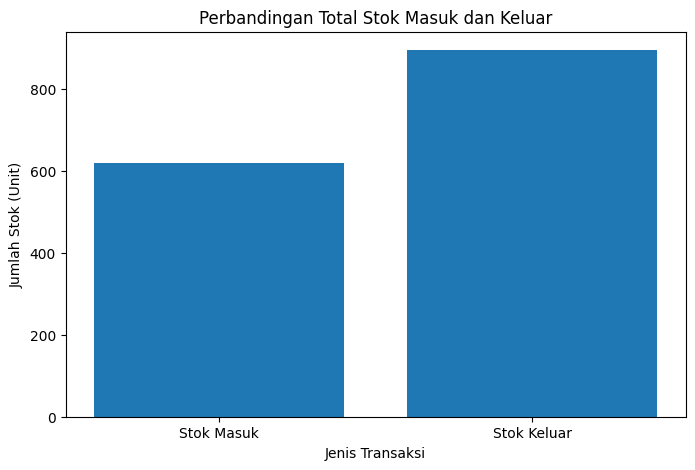

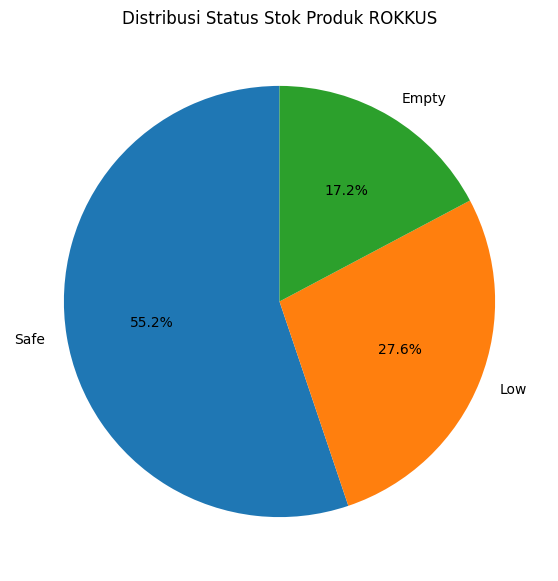

In [24]:
# ======================================
# VISUALISASI ANALISIS BISNIS - ROKKUS
# ======================================

import matplotlib.pyplot as plt

# 1. Grafik perbandingan stok masuk dan keluar
total_masuk = dataset_wrangling["total_masuk"].sum()
total_keluar = dataset_wrangling["total_keluar"].sum()

plt.figure(figsize=(8, 5))

plt.bar(
    ["Stok Masuk", "Stok Keluar"],
    [total_masuk, total_keluar]
)

plt.title("Perbandingan Total Stok Masuk dan Keluar")
plt.xlabel("Jenis Transaksi")
plt.ylabel("Jumlah Stok (Unit)")

plt.show()


# 2. Grafik distribusi status stok
status = ringkasan_status

plt.figure(figsize=(7, 7))

plt.pie(
    status.values,
    labels=status.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Distribusi Status Stok Produk ROKKUS")
plt.show()

## 8. Penyimpanan dan Validasi Output

Pada tahap ini, dataset hasil preprocessing dan ringkasan analisis disimpan dalam format CSV agar dapat digunakan kembali oleh anggota tim. Validasi dilakukan langsung terhadap DataFrame di memori untuk memastikan jumlah data, struktur kolom, dan kualitas dataset utama tetap sesuai. Notebook tidak membaca ulang file CSV lokal sebagai sumber input.

In [25]:
import os

# Membuat folder output
os.makedirs("data/processed", exist_ok=True)
os.makedirs("outputs", exist_ok=True)

# 1. Menyeragamkan urutan kolom dataset
urutan_kolom = [
    "product_id",
    "product_name",
    "category",
    "price",
    "tanggal_stok",
    "stok_awal",
    "total_masuk",
    "total_keluar",
    "stok_akhir",
    "status_stok"
]

dataset_wrangling = dataset_wrangling[urutan_kolom]

# 2. Simpan dataset hasil wrangling dan klasifikasi
dataset_wrangling.to_csv(
    "data/processed/dataset_stok_rokkus_clean.csv",
    index=False
)

# 3. Simpan ringkasan status stok
ringkasan_status.to_csv(
    "outputs/ringkasan_status_stok.csv"
)

# 4. Simpan hasil analisis kategori
analisis_kategori.to_csv(
    "outputs/analisis_stok_per_kategori.csv",
    index=False
)

# 5. Simpan daftar produk yang membutuhkan perhatian
produk_perhatian.to_csv(
    "outputs/produk_low_empty.csv",
    index=False
)

print("=== OUTPUT BERHASIL DISIMPAN ===")
print("1. dataset_stok_rokkus_clean.csv")
print("2. ringkasan_status_stok.csv")
print("3. analisis_stok_per_kategori.csv")
print("4. produk_low_empty.csv")

=== OUTPUT BERHASIL DISIMPAN ===
1. dataset_stok_rokkus_clean.csv
2. ringkasan_status_stok.csv
3. analisis_stok_per_kategori.csv
4. produk_low_empty.csv


In [26]:
# ======================================
# DOKUMENTASI DATA QUALITY
# ======================================

hasil_data_quality = pd.DataFrame([
    ["Master Produk", "Missing Values", 0, "Lolos"],
    ["Stok Awal", "Missing Values", 0, "Lolos"],
    ["Transaksi Stok", "Missing Values", 0, "Lolos"],

    ["Master Produk", "Duplikasi Baris", 0, "Lolos"],
    ["Stok Awal", "Duplikasi Baris", 0, "Lolos"],
    ["Transaksi Stok", "Duplikasi Baris", 0, "Lolos"],

    ["Master Produk", "Duplikasi ID", 0, "Lolos"],
    ["Stok Awal", "Duplikasi ID", 0, "Lolos"],
    ["Transaksi Stok", "Duplikasi ID", 0, "Lolos"],

    ["Relasi Dataset", "ID Produk Tidak Terdaftar", 0, "Lolos"],
    ["Relasi Dataset", "Produk Tanpa Stok Awal", 0, "Lolos"],

    ["Stok Awal", "Tanggal Tidak Valid", 0, "Lolos"],
    ["Transaksi Stok", "Tanggal Tidak Valid", 0, "Lolos"],

    ["Master Produk", "Harga Negatif", 0, "Lolos"],
    ["Stok Awal", "Stok Negatif", 0, "Lolos"],
    ["Transaksi Stok", "Jumlah Negatif", 0, "Lolos"],

    ["Relasi Dataset", "Nama Produk Berbeda", 0, "Lolos"],
    ["Relasi Dataset", "Kategori Berbeda", 0, "Lolos"],
    ["Transaksi Stok", "Jenis Transaksi Tidak Valid", 0, "Lolos"],
    ["Transaksi Stok", "Jumlah Transaksi Nol", 0, "Lolos"],
], columns=[
    "Dataset",
    "Jenis Pemeriksaan",
    "Jumlah Temuan",
    "Status"
])

hasil_data_quality.to_csv(
    "outputs/hasil_data_quality.csv",
    index=False
)

display(hasil_data_quality)

print("Laporan Data Quality berhasil disimpan!")

,Dataset,Jenis Pemeriksaan,Jumlah Temuan,Status
0,Master Produk,Missing Values,0,Lolos
1,Stok Awal,Missing Values,0,Lolos
2,Transaksi Stok,Missing Values,0,Lolos
3,Master Produk,Duplikasi Baris,0,Lolos
4,Stok Awal,Duplikasi Baris,0,Lolos
5,Transaksi Stok,Duplikasi Baris,0,Lolos
6,Master Produk,Duplikasi ID,0,Lolos
7,Stok Awal,Duplikasi ID,0,Lolos
8,Transaksi Stok,Duplikasi ID,0,Lolos
9,Relasi Dataset,ID Produk Tidak Terdaftar,0,Lolos


Laporan Data Quality berhasil disimpan!


In [27]:
# ======================================
# RINGKASAN PREPROCESSING ROKKUS
# ======================================

ringkasan_preprocessing = pd.DataFrame([
    ["Master Produk", 29, 29,
     "Pembersihan spasi dan pemeriksaan tipe data"],

    ["Stok Awal", 29, 29,
     "Pembersihan spasi dan konversi tanggal ke datetime"],

    ["Transaksi Stok", 300, 300,
     "Pembersihan spasi, standarisasi jenis transaksi, dan konversi tanggal"],

    ["Penggabungan Dataset", 29, 29,
     "Penggabungan master produk, stok awal, dan ringkasan transaksi"],

    ["Klasifikasi Stok", 29, 29,
     "Penambahan kolom status Safe, Low, dan Empty"]
], columns=[
    "Tahapan",
    "Jumlah Data Sebelum",
    "Jumlah Data Sesudah",
    "Keterangan"
])

ringkasan_preprocessing.to_csv(
    "outputs/ringkasan_preprocessing.csv",
    index=False
)

display(ringkasan_preprocessing)

print("\nRingkasan preprocessing berhasil disimpan!")

,Tahapan,Jumlah Data Sebelum,Jumlah Data Sesudah,Keterangan
0,Master Produk,29,29,Pembersihan spasi dan pemeriksaan tipe data
1,Stok Awal,29,29,Pembersihan spasi dan konversi tanggal ke date...
2,Transaksi Stok,300,300,"Pembersihan spasi, standarisasi jenis transaks..."
3,Penggabungan Dataset,29,29,"Penggabungan master produk, stok awal, dan rin..."
4,Klasifikasi Stok,29,29,"Penambahan kolom status Safe, Low, dan Empty"



Ringkasan preprocessing berhasil disimpan!


In [28]:
# ======================================
# VALIDASI FILE OUTPUT ROKKUS
# ======================================

import os

daftar_file = [
    "data/processed/dataset_stok_rokkus_clean.csv",
    "outputs/ringkasan_status_stok.csv",
    "outputs/analisis_stok_per_kategori.csv",
    "outputs/produk_low_empty.csv",
    "outputs/hasil_data_quality.csv",
    "outputs/ringkasan_preprocessing.csv"
]

print("=== VALIDASI FILE OUTPUT ===")
for file in daftar_file:
    if os.path.exists(file):
        print("BERHASIL:", file)
    else:
        print("BELUM ADA:", file)

# Validasi dataset utama langsung dari DataFrame di memori,
# tanpa membaca ulang CSV dari folder lokal.
kolom_diharapkan = [
    "product_id", "product_name", "category", "price",
    "tanggal_stok", "stok_awal", "total_masuk",
    "total_keluar", "stok_akhir", "status_stok"
]

print("\n=== VALIDASI DATASET UTAMA ===")
print("Jumlah produk:", len(dataset_wrangling))
print("Jumlah kolom:", len(dataset_wrangling.columns))
print("Urutan kolom benar:", dataset_wrangling.columns.tolist() == kolom_diharapkan)
print("Total stok akhir:", dataset_wrangling["stok_akhir"].sum())
print("Duplikasi ID:", dataset_wrangling["product_id"].duplicated().sum())
print("Missing values:", dataset_wrangling.isnull().sum().sum())


=== VALIDASI FILE OUTPUT ===
BERHASIL: data/processed/dataset_stok_rokkus_clean.csv
BERHASIL: outputs/ringkasan_status_stok.csv
BERHASIL: outputs/analisis_stok_per_kategori.csv
BERHASIL: outputs/produk_low_empty.csv
BERHASIL: outputs/hasil_data_quality.csv
BERHASIL: outputs/ringkasan_preprocessing.csv

=== VALIDASI DATASET UTAMA ===
Jumlah produk: 29
Jumlah kolom: 10
Urutan kolom benar: True
Total stok akhir: 332
Duplikasi ID: 0
Missing values: 0


## 7. Kesimpulan dan Rekomendasi

### Kesimpulan

Berdasarkan proses analisis dan preprocessing terhadap dataset sintetis UMKM ROKKUS Mardani Raya periode 1–30 September 2026, diperoleh tiga dataset utama, yaitu master produk sebanyak 29 data, stok awal sebanyak 29 data, dan transaksi stok sebanyak 300 data.

Hasil pemeriksaan kualitas data menunjukkan bahwa tidak ditemukan missing values, duplikasi data, duplikasi ID, ketidaksesuaian relasi produk, maupun nilai negatif pada kolom numerik yang diperiksa.

Proses data cleaning dilakukan melalui pembersihan spasi, standarisasi jenis transaksi, dan konversi format tanggal. Selanjutnya, data wrangling dilakukan dengan menggabungkan master produk, stok awal, dan ringkasan transaksi untuk memperoleh informasi persediaan setiap produk.

Berdasarkan hasil perhitungan, diperoleh total stok awal sebanyak 608 unit, stok masuk sebanyak 620 unit, stok keluar sebanyak 896 unit, dan stok akhir sebanyak 332 unit.

Hasil klasifikasi menunjukkan bahwa terdapat 16 produk berstatus Safe, 8 produk berstatus Low, dan 5 produk berstatus Empty.

Dataset hasil pengolahan terdiri atas 29 produk dan 10 kolom, tanpa missing values maupun duplikasi ID. Dataset tersebut dapat digunakan sebagai dasar untuk tahapan pengembangan model AI berikutnya setelah kebutuhan fitur dan target model disepakati oleh tim.

### Rekomendasi

1. Memprioritaskan pemantauan terhadap lima produk yang memiliki stok akhir nol.
2. Melakukan pemantauan berkala terhadap delapan produk berstatus Low.
3. Mengevaluasi pola stok masuk dan stok keluar sebagai bahan pertimbangan pengadaan persediaan.
4. Mengembangkan fitur pemantauan stok yang dapat membantu UMKM mengetahui kondisi persediaan setiap produk.
5. Melakukan koordinasi dengan tim Generative AI untuk menentukan kebutuhan fitur dan target model sebelum menerapkan preprocessing khusus machine learning.

**Catatan:** Seluruh hasil analisis menggunakan dataset sintetis sehingga belum menggambarkan kondisi transaksi operasional aktual UMKM ROKKUS Mardani Raya.

In [29]:
import shutil

shutil.make_archive(
    "ROKKUS_Output_Final",
    "zip",
    "outputs"
)

from google.colab import files
files.download("ROKKUS_Output_Final.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [30]:
import shutil
from google.colab import files

# Menggabungkan folder data dan outputs
shutil.make_archive(
    "ROKKUS_Data_Preprocessing",
    "zip",
    root_dir=".",
    base_dir="data/processed"
)

# Buat ZIP khusus outputs
shutil.make_archive(
    "ROKKUS_Outputs",
    "zip",
    root_dir=".",
    base_dir="outputs"
)

files.download("ROKKUS_Data_Preprocessing.zip")
files.download("ROKKUS_Outputs.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>